Urządzenie: cuda

=== TRENING WARIANTÓW REDUKCJI (CIFAR-10) ===
Max Pooling (2x2)          | Mapa: (128, 4, 4)  | Parametry:  94,986 | Test Acc:  71.24% | Czas:  60.7s
Average Pooling (2x2)      | Mapa: (128, 4, 4)  | Parametry:  94,986 | Test Acc:  69.76% | Czas:  59.7s
Splot z krokiem (stride=2) | Mapa: (128, 4, 4)  | Parametry: 289,194 | Test Acc:  76.11% | Czas:  60.4s


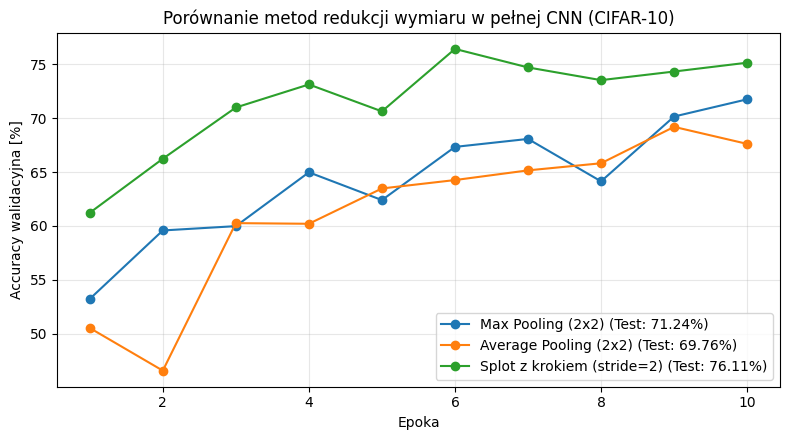

In [1]:
import os
import time
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Urządzenie:", device)

if not os.path.exists("./data/cifar-10-batches-py"):
    os.makedirs("./data", exist_ok=True)
    os.system("wget -q https://storage.googleapis.com/tensorflow/tf-keras-datasets/cifar-10-python.tar.gz -O ./data/cifar-10-python.tar.gz")
    os.system("tar -xzf ./data/cifar-10-python.tar.gz -C ./data/")

mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

full_train = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=tf)
test_ds    = torchvision.datasets.CIFAR10("./data", train=False, download=False, transform=tf)
train_ds, val_ds = random_split(full_train, [45000, 5000], generator=torch.Generator().manual_seed(42))

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

class FullCNN(nn.Module):
    def __init__(self, n_classes=10, reduction="max"):
        super().__init__()
        def make_block(cin, cout):
            layers = [
                nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU()
            ]
            if reduction == "max":
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            elif reduction == "avg":
                layers.append(nn.AvgPool2d(kernel_size=2, stride=2))
            elif reduction == "stride":
                layers.extend([
                    nn.Conv2d(cout, cout, kernel_size=3, stride=2, padding=1),
                    nn.BatchNorm2d(cout),
                    nn.ReLU()
                ])
            return nn.Sequential(*layers)

        self.features = nn.Sequential(
            make_block(3, 32),
            make_block(32, 64),
            make_block(64, 128)
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128, n_classes)
        )

    def forward(self, x):
        return self.head(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def evaluate(model, dl):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item()
            total += yb.numel()
    return correct / total

def train_variant(variant, epochs=10, lr=1e-3):
    model = FullCNN(reduction=variant).to(device)
    with torch.no_grad():
        dummy_fmap = model.features(torch.zeros(1, 3, 32, 32, device=device))
    fmap_shape = tuple(dummy_fmap.shape[1:])  # (C, H, W)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    val_accs = []
    best_val = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        val_acc = evaluate(model, val_dl)
        val_accs.append(val_acc)
        if val_acc > best_val:
            best_val = val_acc
            best_weights = copy.deepcopy(model.state_dict())

    dt = time.time() - t0
    model.load_state_dict(best_weights)
    test_acc = evaluate(model, test_dl)
    return val_accs, test_acc, count_params(model), fmap_shape, dt

EPOCHS = 10
variants = ["max", "avg", "stride"]
labels = {"max": "Max Pooling (2x2)", "avg": "Average Pooling (2x2)", "stride": "Splot z krokiem (stride=2)"}
summary = {}

print("\n=== TRENING WARIANTÓW REDUKCJI (CIFAR-10) ===")
for v in variants:
    val_accs, test_acc, params, fmap_shape, dt = train_variant(v, epochs=EPOCHS)
    summary[v] = (val_accs, test_acc, params, fmap_shape, dt)
    print(f"{labels[v]:26} | Mapa: {str(fmap_shape):12} | Parametry: {params:>7,} | Test Acc: {test_acc*100:>6.2f}% | Czas: {dt:>5.1f}s")

plt.figure(figsize=(8, 4.5))
for v in variants:
    val_accs, test_acc, _, _, _ = summary[v]
    plt.plot(range(1, EPOCHS+1), [a*100 for a in val_accs], "o-", label=f"{labels[v]} (Test: {test_acc*100:.2f}%)")

plt.xlabel("Epoka")
plt.ylabel("Accuracy walidacyjna [%]")
plt.title("Porównanie metod redukcji wymiaru w pełnej CNN (CIFAR-10)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()